---
title: "L5-02 · Gates and circuit order"
short_title: "Gates and circuit order"
subtitle: "Gates are unitary matrices, and on one qubit they are rotations of the Bloch sphere; a circuit applies them in time order, so its matrix is the product written in reverse, and because rotations do not commute, the order can change the result."
description: "Apply unitary gates in the correct order, reading a circuit left to right while multiplying its matrices right to left, and describe each single-qubit gate as a rotation of the Bloch sphere."
tags: [level-5, coursebook]
---

(lesson-l5-02)=

:::{div}
:class: qcai-meta
![Level 5 icon](../../_static/icons/qicon-level-5.svg) **Level 5 · Advanced undergraduate** · about 90 minutes  
**Big idea.** Gates are unitary matrices, and on one qubit they are rotations of the Bloch sphere; a circuit applies them in time order, so its matrix is the product written in reverse, and because rotations do not commute, the order can change the result.  
**Before this lesson.** [L5-01](#lesson-l5-01), [L3-03](#lesson-l3-03)  
**Lab.** [Qubits and the Bloch sphere](../../labs/05-qubit-bloch.ipynb)
:::

## What you will be able to do

- Verify that a matrix is unitary and explain why unitarity is exactly the condition that keeps every state normalized.
- Write the matrix $U_m \cdots U_1$ of a circuit and of its inverse from the diagram, and compute the output state.
- Identify $X$, $Y$, $Z$, $H$, $S$ and $T$ as Bloch-sphere rotations, giving the axis and angle up to a global phase.
- Decide by computation whether two gates commute, and give an example in which the order changes a measurement probability.

## Why this matters

Apply a Hadamard and then the phase gate $S$ to $|0\rangle$: you get $|{+i}\rangle$. Apply the same two gates in the opposite order: you get $|+\rangle$. Measured in the X basis, the first state gives $+$ half the time and the second gives $+$ every time. With numbers, $2 \cdot 3 = 3 \cdot 2$; with gates, the order is part of the program. A classic slip makes the same point from the other side: the circuit diagram lists gates in time order from left to right, but the matrix that the circuit implements lists them from right to left.

Why are gates unitary at all? The Born rule of [L5-01](#lesson-l5-01) needs the squared amplitudes to add to 1 after every operation, and we will prove that the linear maps that keep every state normalized are exactly the unitaries. On a single qubit they have a beautiful picture: each one turns the Bloch sphere rigidly about some axis. That picture makes identities such as $HZH = X$ visible, and it prepares the interference circuits of [L5-03](#lesson-l5-03).

:::{dropdown} Key terms

**Unitary matrix**
: A square complex matrix with $U^\dagger U = I$, where $U^\dagger$ is the conjugate transpose.

**Quantum gate**
: A unitary matrix applied to the state, $|\psi\rangle \mapsto U|\psi\rangle$.

**Circuit diagram**
: A picture of a computation in which time runs left to right along each qubit's wire, and boxes are gates.

**Pauli matrices**
: $X$, $Y$, $Z$: the bit flip, the combined flip with phase, and the phase flip; half turns about the three axes.

**Hadamard gate**
: $H = \frac{1}{\sqrt2}\begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix}$, a half turn about the axis halfway between $x$ and $z$.

**Phase gates S and T**
: $S = \operatorname{diag}(1, i)$ and $T = \operatorname{diag}(1, e^{i\pi/4})$: quarter and eighth turns about the $z$ axis.

**Commutator**
: $[A, B] = AB - BA$; the gates commute exactly when it is the zero matrix.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l5_02 as _lessonfigs

## Gates are unitary matrices

A gate on one qubit is a $2 \times 2$ complex matrix $U$ acting by $|\psi\rangle \mapsto U|\psi\rangle$. For the result to be a state again, $U$ must send every unit vector to a unit vector. Matrix-vector multiplication is reviewed in [L3-03](#lesson-l3-03) [@openstax_matrices].

:::{prf:definition} Adjoint and unitary
:label: def-l5-02-unitary
The **adjoint** $U^\dagger$ is the conjugate transpose of $U$, so $(U^\dagger)_{jk} = \overline{U_{kj}}$ and $\langle\phi|U\psi\rangle = \langle U^\dagger\phi|\psi\rangle$. A square matrix is **unitary** if $U^\dagger U = I$. Equivalently, its columns form an orthonormal basis.
:::

:::{prf:theorem} Unitaries are exactly the norm-preserving linear maps
:label: thm-l5-02-norm
For a linear map $U$ on $\mathbb{C}^n$, $\|U v\| = \|v\|$ for every vector $v$ if and only if $U^\dagger U = I$.
:::

:::{prf:proof}
If $U^\dagger U = I$ then $\|Uv\|^2 = \langle Uv|Uv\rangle = \langle v|U^\dagger U v\rangle = \|v\|^2$. Conversely, put $A = U^\dagger U - I$, so $f(v) = \langle v|Av\rangle = \|Uv\|^2 - \|v\|^2 = 0$ for every $v$. Expanding $f(u + cw) = f(u) + c\langle u|Aw\rangle + \bar c\langle w|Au\rangle + |c|^2 f(w)$ and summing with $c = i^k$ gives the polarization identity $\langle u|Aw\rangle = \frac14\sum_{k=0}^{3} i^{-k} f(u + i^k w)$, because $\sum_k i^{-k} = \sum_k i^{-2k} = 0$ and $\sum_k i^{-k} i^{k} = 4$. Every term on the right is 0, so $\langle u|Aw\rangle = 0$ for all $u, w$, and $A = 0$.
:::

$$
X = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix}, \ Y = \begin{pmatrix} 0 & -i \\ i & 0 \end{pmatrix}, \ Z = \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix}, \ H = \tfrac{1}{\sqrt2}\begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix}, \ S = \begin{pmatrix} 1 & 0 \\ 0 & i \end{pmatrix}, \ T = \begin{pmatrix} 1 & 0 \\ 0 & e^{i\pi/4} \end{pmatrix}
$$ (eq-l5-02-gates)

Each matrix in [](#eq-l5-02-gates) has orthonormal columns. For $H$: the columns $\frac{1}{\sqrt2}(1, 1)$ and $\frac{1}{\sqrt2}(1, -1)$ have length 1 and inner product $\frac12(1 - 1) = 0$. Since $H$ is real and symmetric, $H^\dagger = H$ and so $H^2 = I$: applying a Hadamard twice does nothing. $X$ maps $|0\rangle \leftrightarrow |1\rangle$, $Z$ flips the sign of $|1\rangle$, and $H$ maps $|0\rangle \mapsto |+\rangle$, $|1\rangle \mapsto |-\rangle$. A unitary is always reversible: its inverse is $U^\dagger$.

## Gates rotate the Bloch sphere

:::{prf:definition} Rotation operators
:label: def-l5-02-rot
For a unit vector $\hat n = (n_x, n_y, n_z)$ and an angle $\theta$, $R_{\hat n}(\theta) = \cos\frac{\theta}{2}\,I - i\sin\frac{\theta}{2}\,(n_x X + n_y Y + n_z Z)$. In particular $R_z(\theta) = \operatorname{diag}(e^{-i\theta/2}, e^{i\theta/2})$.
:::

:::{prf:theorem} Rotation operators rotate Bloch vectors
:label: thm-l5-02-rot
$R_{\hat n}(\theta)$ maps the state with Bloch vector $\vec r$ to the state whose Bloch vector is $\vec r$ rotated by the angle $\theta$ about $\hat n$, counterclockwise when $\hat n$ points at you (right-hand rule). Every single-qubit unitary equals $e^{i\gamma}R_{\hat n}(\theta)$ for some phase $\gamma$, axis $\hat n$ and angle $\theta$ [@nielsenchuang].
:::

:::{prf:proof}
Proof for the $z$ axis, sketch for the rest. Write a state as $\cos\frac{\vartheta}{2}|0\rangle + e^{i\varphi}\sin\frac{\vartheta}{2}|1\rangle$ (Theorem [](#thm-l5-01-bloch) of [L5-01](#lesson-l5-01)). Then $R_z(\theta)$ gives $e^{-i\theta/2}\big(\cos\frac{\vartheta}{2}|0\rangle + e^{i(\varphi + \theta)}\sin\frac{\vartheta}{2}|1\rangle\big)$: a global phase times the state with azimuth $\varphi + \theta$, which is the Bloch vector turned by $\theta$ about $z$. For another axis, pick a unitary $V$ that carries the $z$ axis to $\hat n$; then $R_{\hat n}(\theta) = V R_z(\theta) V^\dagger$, and the action is conjugated in the same way. The decomposition of a general unitary follows by removing the phase $\sqrt{\det U}$ and matching the remaining matrix of determinant 1 to the form in the definition; Section 4.2 of Nielsen and Chuang gives the details.
:::

$$
X = i\,R_x(\pi), \quad Z = i\,R_z(\pi), \quad H = i\,R_{\hat n}(\pi) \text{ with } \hat n = \tfrac{1}{\sqrt2}(1, 0, 1), \quad S = e^{i\pi/4} R_z(\pi/2), \quad T = e^{i\pi/8} R_z(\pi/4)
$$ (eq-l5-02-rotations)

Check the Hadamard: with $\hat n = (1, 0, 1)/\sqrt2$, $R_{\hat n}(\pi) = -i\,\frac{X + Z}{\sqrt2} = -iH$, so $H = i\,R_{\hat n}(\pi)$. A half turn about $\hat n$ sends $\vec r$ to $2(\hat n\cdot\vec r)\hat n - \vec r$, which is $(x, y, z) \mapsto (z, -y, x)$: the $x$ and $z$ axes swap and $y$ reverses. Likewise $S$ is a quarter turn about $z$ (so $|+\rangle \mapsto |{+i}\rangle$), and $S^2 = Z$ is a half turn. Global phases such as $i$ and $e^{i\pi/4}$ are invisible ([L5-01](#lesson-l5-01)), so on the sphere a gate is just its rotation.

:::{figure} ../../_static/animations/l5_02_gates_as_rotations.mp4
:alt: A Bloch vector starts at the north pole and is turned by four gates in turn, H, S, S, H, each as a rotation about a dashed axis, ending at the south pole; a circuit row grows at the top right.
:width: 100%

The circuit $H, S, S, H$ as four rigid rotations: $|0\rangle \to |+\rangle \to |{+i}\rangle \to |-\rangle \to |1\rangle$. Since $S^2 = Z$, this is $HZH = X$.
:::

:::{dropdown} What the animation shows
A Bloch sphere is drawn with the state arrow at $|0\rangle$. At the top right a wire labeled $|0\rangle$ collects a box for each gate as it is applied. First $H$, described as $H = i\,R_{\hat n}(\pi)$ with $\hat n = (x + z)/\sqrt2$: a dashed axis appears halfway between $x$ and $z$, and the arrow swings through a half turn about it, leaving a violet arc and ending at $|+\rangle$ on the $x$ axis. Second $S = e^{i\pi/4}R_z(\pi/2)$: the arrow turns a quarter turn about the vertical axis to $|{+i}\rangle$ on the $y$ axis (cyan arc). Third, another $S$: a further quarter turn to $|-\rangle$ (amber arc). Fourth, $H$ again: a half turn about the diagonal axis carries $|-\rangle$ to $|1\rangle$ at the south pole (blue arc). The scene ends with $H\,S\,S\,H = HZH = X$ and $X|0\rangle = |1\rangle$, and the reminder that the first gate in time is the rightmost factor.
:::


In [2]:
_show(_lessonfigs.circuit_explorer())

**Explore.** Pick a short circuit. Each gate's rotation arc is drawn in turn (violet, cyan, amber, blue), and the title gives the output state, with the global phase removed, and $P(0)$.

:::{dropdown} What the figure shows
A 3-D Bloch sphere with the six axis states labeled. A menu offers the circuits H; H then S; S then H; H, S, S, H; H, T, H; X then H; H then X, all applied to $|0\rangle$. For each, the figure draws the true rotation arc of every gate and the final Bloch vector, and the title states the result. H gives $0.707|0\rangle + 0.707|1\rangle$; H then S gives $0.707|0\rangle + 0.707i|1\rangle$; S then H gives $0.707|0\rangle + 0.707|1\rangle$; H, S, S, H gives $|1\rangle$; H, T, H gives $0.924|0\rangle - 0.383i|1\rangle$ with $P(0) = 0.854$; X then H gives $|-\rangle$; H then X gives $|+\rangle$.
:::

## Circuit order and matrix order

In a circuit diagram time runs from left to right. If the gates along the wire are $U_1$ (first, leftmost), then $U_2$, up to $U_m$, the state after the circuit is $U_m(\cdots(U_2(U_1|\psi\rangle)))$. Matrix multiplication is associative, so we may drop the brackets, but not reorder the factors: the first gate in time is the factor next to the ket.

$$
|\psi_{\text{out}}\rangle = U_m \cdots U_2\, U_1\,|\psi\rangle, \qquad (U_m \cdots U_1)^\dagger = U_1^\dagger \cdots U_m^\dagger
$$ (eq-l5-02-order)

:::{prf:proposition} The matrix of a circuit and of its inverse
:label: prop-l5-02-inverse
If $U_1, \dots, U_m$ are unitary, so is $U = U_m \cdots U_1$, and $U^{-1} = U^\dagger = U_1^\dagger \cdots U_m^\dagger$. In circuit terms, the inverse circuit runs the gates backwards in time, replacing each by its adjoint.
:::

:::{prf:proof}
For two factors, $(AB)^\dagger = B^\dagger A^\dagger$ (transpose and conjugate both reverse products), so $(AB)^\dagger(AB) = B^\dagger A^\dagger A B = B^\dagger B = I$. Induction on $m$ gives the general case, and $U^\dagger U = I$ means $U^\dagger$ is the inverse. Reading $U_1^\dagger \cdots U_m^\dagger$ as a circuit, the rightmost factor $U_m^\dagger$ acts first.
:::

:::{figure} ../../_static/animations/l5_02_circuit_order.mp4
:alt: A circuit with boxes H, Z, H on a wire, the product H Z H written with colors reversed, a matrix multiplication that collapses to X, and then two equations showing that SH and HS send zero to different states.
:width: 100%

The circuit $H, Z, H$ is the matrix $HZH$; multiplying it out gives $HZH = X$. Then the two orders of $H$ and $S$ give different states.
:::

:::{dropdown} What the animation shows
A wire carries $|\psi\rangle$ through three boxes, H (violet), Z (cyan) and H (amber), with an arrow labeled time pointing right. Beside it the product $H\,Z\,H\,|\psi\rangle$ is written with the colors reversed: the violet H, the first gate in time, is the rightmost factor, next to the ket, with an arrow labeled acts first pointing left. Below, the product is multiplied out term by term: $HZH = \frac12 \begin{pmatrix}1&1\\1&-1\end{pmatrix}\begin{pmatrix}1&0\\0&-1\end{pmatrix}\begin{pmatrix}1&1\\1&-1\end{pmatrix}$, then $\frac12\begin{pmatrix}1&1\\1&-1\end{pmatrix}\begin{pmatrix}1&1\\-1&1\end{pmatrix}$, then $\frac12\begin{pmatrix}0&2\\2&0\end{pmatrix}$, and finally $\begin{pmatrix}0&1\\1&0\end{pmatrix} = X$, which is boxed. Last, two lines compare the orders of $H$ and $S$ on $|0\rangle$: $S H|0\rangle = S|+\rangle = |{+i}\rangle$ but $H S|0\rangle = H|0\rangle = |+\rangle$, so $SH \neq HS$: order changes the state.
:::

:::{prf:example} HZH = X by multiplication
:label: ex-l5-02-hzh
First $ZH$, the two factors on the right: $Z\begin{pmatrix}1&1\\1&-1\end{pmatrix} = \begin{pmatrix}1&1\\-1&1\end{pmatrix}$ (the second row changes sign). Then $\begin{pmatrix}1&1\\1&-1\end{pmatrix}\begin{pmatrix}1&1\\-1&1\end{pmatrix} = \begin{pmatrix}0&2\\2&0\end{pmatrix}$. With the factor $\frac{1}{\sqrt2}\cdot\frac{1}{\sqrt2} = \frac12$, this is $HZH = X$. On the sphere: $H$ swaps the $x$ and $z$ axes, so a half turn about $z$ seen through $H$ becomes a half turn about $x$.
:::

```{mermaid}
graph LR
  A[input state] --> G1[H]
  G1 --> G2[T]
  G2 --> G3[S]
  G3 --> M[measure]
  G3 -.-> W[matrix S T H]
```

*Gates in time order H, T, S implement the matrix S T H: the product lists the same gates in reverse.*

## When order matters: commutators

:::{prf:definition} Commutator
:label: def-l5-02-comm
The **commutator** of two matrices is $[A, B] = AB - BA$. The circuits "$A$, then $B$" and "$B$, then $A$" have matrices $BA$ and $AB$, which agree exactly when $[A, B] = 0$.
:::

:::{prf:proposition} Which standard gates commute
:label: prop-l5-02-comm
(a) Diagonal gates commute with each other; in particular $Z$, $S$, $T$ and every $R_z(\theta)$ commute. (b) $X$ and $Z$ anticommute: $XZ = -ZX$, so $[X, Z] = -2iY$. (c) $H$ and $S$ do not commute, even up to a global phase.
:::

:::{prf:proof}
(a) Diagonal matrices multiply entry by entry, and complex numbers commute. (b) $XZ = \begin{pmatrix}0&-1\\1&0\end{pmatrix}$ and $ZX = \begin{pmatrix}0&1\\-1&0\end{pmatrix} = -XZ$, so $[X, Z] = 2XZ = \begin{pmatrix}0&-2\\2&0\end{pmatrix} = -2iY$. (c) $SH|0\rangle = |{+i}\rangle$ while $HS|0\rangle = |+\rangle$. These are different points of the Bloch sphere, so no global phase relates $SH$ and $HS$.
:::

:::{figure} ../../_static/animations/l5_02_order_matters.mp4
:alt: Two Bloch spheres side by side. On the left, H then S moves the arrow from the north pole to the x axis and then to the y axis; on the right, S leaves the north pole in place and H then moves the arrow to the x axis.
:width: 100%

Same two gates, opposite order: $S H|0\rangle = |{+i}\rangle$ but $H S|0\rangle = |+\rangle$, and an X measurement tells them apart.
:::

:::{dropdown} What the animation shows
Two Bloch spheres are shown, labeled H, then S on the left and S, then H on the right; both arrows start at $|0\rangle$. In step 1 the left arrow makes a half turn about the diagonal axis $(x + z)/\sqrt2$ to $|+\rangle$, while on the right $S$, a quarter turn about the vertical axis, leaves $|0\rangle$ where it is, because $S|0\rangle = |0\rangle$. In step 2 the left arrow turns a quarter turn about $z$ from $|+\rangle$ to $|{+i}\rangle$ on the $y$ axis, while the right arrow makes the Hadamard half turn from $|0\rangle$ to $|+\rangle$ on the $x$ axis. The results are written under the spheres: $S H|0\rangle = |{+i}\rangle$ and $H S|0\rangle = |+\rangle$, and the X-basis probabilities differ: $P(+) = 0.5$ versus $P(+) = 1$.
:::


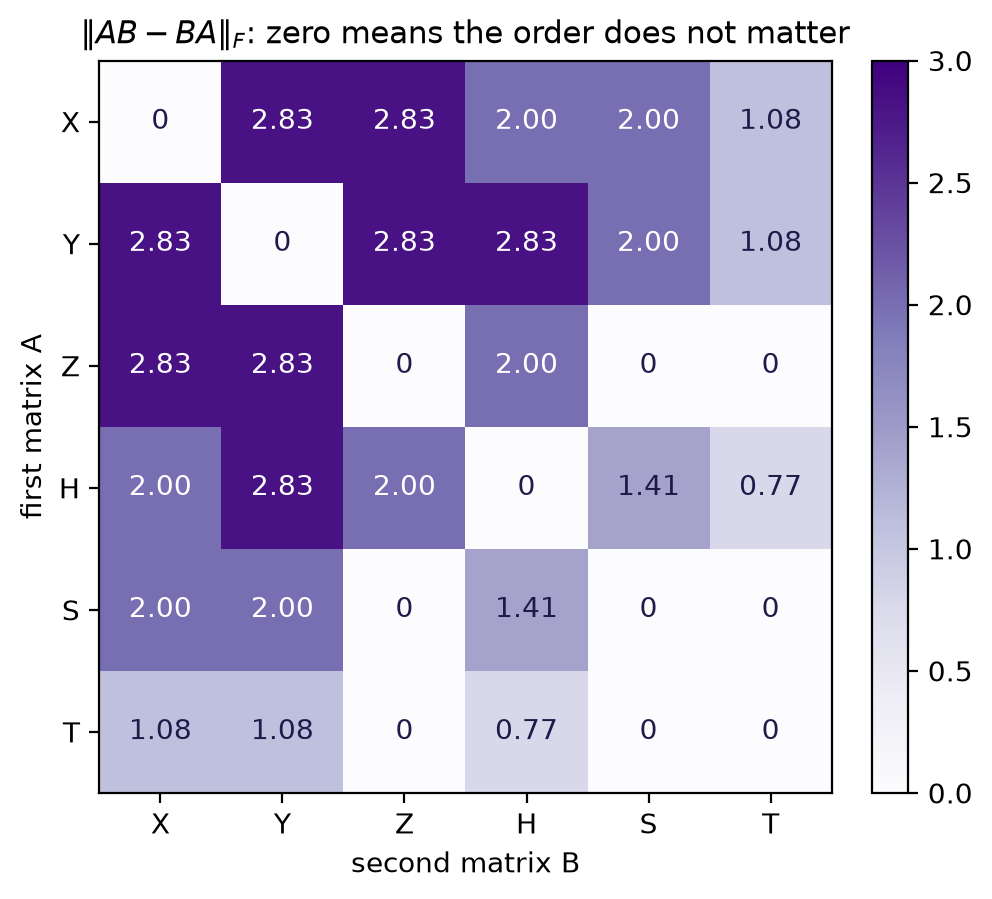

In [3]:
_show_mpl(_lessonfigs.commutator_map())

*How far each pair of standard gates is from commuting: the Frobenius norm $\|AB - BA\|_F$. The zeros are the diagonal gates $Z$, $S$, $T$ among themselves (and every gate with itself).*

:::{prf:remark} Order up to a global phase
A nonzero commutator does not always mean a visible difference. Since $XZ = -ZX$, the circuits "$X$, then $Z$" and "$Z$, then $X$" produce states that differ only by the global phase $-1$, so every measurement gives the same probabilities. Physically, order matters when $AB \neq e^{i\gamma}BA$ for every phase $\gamma$, as for $H$ and $S$.
:::

## Compute it

Check unitarity and the gate identities, run the two orders of H and S, recover each gate's rotation axis and angle, and test commutators.


In [4]:
import numpy as np
from qcai import science

X, Y, Z, H, I2 = science.X, science.Y, science.Z, science.H, science.I2
S = np.diag([1, 1j])
T = np.diag([1, np.exp(1j * np.pi / 4)])
gates = {'X': X, 'Y': Y, 'Z': Z, 'H': H, 'S': S, 'T': T}

# 1. every gate is unitary: U^dagger U = I
print('unitary:', all(np.allclose(U.conj().T @ U, I2) for U in gates.values()))

# 2. gate identities
print('HZH = X:', np.allclose(H @ Z @ H, X), '  HXH = Z:', np.allclose(H @ X @ H, Z),
      '  SS = Z:', np.allclose(S @ S, Z), '  TT = S:', np.allclose(T @ T, S))

# 3. circuit order: the first gate in time is the rightmost factor
for name, U in (('H, then S', S @ H), ('S, then H', H @ S)):
    out = U @ science.KET0
    print(f'{name}:  Bloch vector {np.round(science.bloch(science.dm(out)), 3)}   P(+) = {abs(out.sum()) ** 2 / 2:.3f}')

# 4. axis and angle: remove the global phase, then read V = cos(a/2) I - i sin(a/2) n.sigma
def axis_angle(U):
    V = U / np.sqrt(np.linalg.det(U))
    a = 2 * np.arccos(np.clip(np.real(np.trace(V)) / 2, -1, 1))
    n = np.real([1j * np.trace(V @ P) / 2 for P in (X, Y, Z)]) / np.sin(a / 2)
    return round(float(np.degrees(a)), 2), np.round(n, 4) + 0.0
for k in 'XHST':
    print(k, ' angle (deg), axis:', *axis_angle(gates[k]))

# 5. commutators
comm = lambda A, B: A @ B - B @ A
print('[X, Z] = -2iY:', np.allclose(comm(X, Z), -2j * Y), '   [S, T] = 0:', np.allclose(comm(S, T), 0),
      '   [H, S] = 0:', np.allclose(comm(H, S), 0))

# 6. worked example: H, then T, then H on |0>
out = H @ T @ H @ science.KET0
print('HTH|0>: P(0) =', round(abs(out[0]) ** 2, 4), '  (1 + cos(pi/4))/2 =', round((1 + np.cos(np.pi / 4)) / 2, 4),
      '  Bloch', np.round(science.bloch(science.dm(out)), 4) + 0.0)

unitary: True
HZH = X: True   HXH = Z: True   SS = Z: True   TT = S: True
H, then S:  Bloch vector [0. 1. 0.]   P(+) = 0.500
S, then H:  Bloch vector [1. 0. 0.]   P(+) = 1.000
X  angle (deg), axis: 180.0 [1. 0. 0.]
H  angle (deg), axis: 180.0 [0.7071 0.     0.7071]
S  angle (deg), axis: 90.0 [0. 0. 1.]
T  angle (deg), axis: 45.0 [0. 0. 1.]
[X, Z] = -2iY: True    [S, T] = 0: True    [H, S] = 0: False
HTH|0>: P(0) = 0.8536   (1 + cos(pi/4))/2 = 0.8536   Bloch [ 0.     -0.7071  0.7071]


:::{tip} A habit that prevents order bugs
When you translate a circuit into matrices, write the ket first and then add each gate to its left as you move right along the wire: $|\psi\rangle$, $U_1|\psi\rangle$, $U_2 U_1|\psi\rangle$, and so on. Software libraries that build circuits gate by gate do exactly this.
:::

## Worked example

:::{admonition} Hadamard, T, Hadamard
:class: tip

Apply the circuit $H$, then $T$, then $H$ to $|0\rangle$. Find the output state, $P(0)$, and the Bloch vector, both by matrices and by rotations.

1. The circuit matrix is $HTH$ (first gate on the right). $H|0\rangle = |+\rangle = \frac{1}{\sqrt2}(|0\rangle + |1\rangle)$ and $T|+\rangle = \frac{1}{\sqrt2}(|0\rangle + e^{i\pi/4}|1\rangle)$.
2. Then $H$ gives $\frac12\big((1 + e^{i\pi/4})|0\rangle + (1 - e^{i\pi/4})|1\rangle\big) = e^{i\pi/8}\big(\cos\frac{\pi}{8}|0\rangle - i\sin\frac{\pi}{8}|1\rangle\big)$, using $1 \pm e^{ix} = e^{ix/2}(e^{-ix/2} \pm e^{ix/2})$.
3. Born rule: $P(0) = \frac{|1 + e^{i\pi/4}|^2}{4} = \frac{2 + 2\cos(\pi/4)}{4} = \frac{1 + \cos 45^\circ}{2} \approx 0.854$.
4. Rotations: $H$ takes $(0, 0, 1)$ to $(1, 0, 0)$; $T$ turns it $45^\circ$ about $z$ to $(0.707, 0.707, 0)$; $H$ maps $(x, y, z) \mapsto (z, -y, x)$, giving $(0, -0.707, 0.707)$. Check: $(1 + z)/2 = (1 + 0.707)/2 \approx 0.854$.

**Result.** $HTH|0\rangle = e^{i\pi/8}(\cos\frac{\pi}{8}|0\rangle - i\sin\frac{\pi}{8}|1\rangle)$, with $P(0) = \cos^2\frac{\pi}{8} \approx 0.854$ and Bloch vector $(0, -0.707, 0.707)$. The phase $\pi/4$ added by $T$ became a change in a computational-basis probability, which is the theme of [L5-03](#lesson-l5-03).
:::

## Exercises

**1. (Core)** Verify $HXH = Z$ by multiplying the matrices.

:::{dropdown} Solution
$HX = \frac{1}{\sqrt2}\begin{pmatrix}1&1\\-1&1\end{pmatrix}$ (multiplying by $X$ on the right swaps the columns of $H$). Then $(HX)H = \frac12\begin{pmatrix}1&1\\-1&1\end{pmatrix}\begin{pmatrix}1&1\\1&-1\end{pmatrix} = \frac12\begin{pmatrix}2&0\\0&-2\end{pmatrix} = Z$.
:::

**2. (Core)** Find the output of the circuits "$X$, then $H$" and "$H$, then $X$" on $|0\rangle$, and the probability of $+$ in an X measurement for each.

:::{dropdown} Solution
"$X$, then $H$" is $HX|0\rangle = H|1\rangle = |-\rangle$, so $P(+) = 0$. "$H$, then $X$" is $XH|0\rangle = X|+\rangle = |+\rangle$, so $P(+) = 1$. Order changes a probability from 0 to 1.
:::

**3. (Stretch)** Show that $S^2 = Z$, $T^2 = S$ and $T^8 = I$, and check that $T = e^{i\pi/8}R_z(\pi/4)$.

:::{dropdown} Solution
These are diagonal: $S^2 = \operatorname{diag}(1, i^2) = Z$; $T^2 = \operatorname{diag}(1, e^{i\pi/2}) = S$; $T^8 = \operatorname{diag}(1, e^{2\pi i}) = I$. And $R_z(\pi/4) = \operatorname{diag}(e^{-i\pi/8}, e^{i\pi/8})$, so $e^{i\pi/8}R_z(\pi/4) = \operatorname{diag}(1, e^{i\pi/4}) = T$.
:::

**4. (Stretch)** A circuit applies $H$, then $T$, then $S$. Write its matrix and the matrix and gate order of the inverse circuit, and check that they multiply to $I$.

:::{dropdown} Solution
The matrix is $U = STH$. Its inverse is $U^\dagger = H^\dagger T^\dagger S^\dagger = H T^\dagger S^\dagger$, which as a circuit applies $S^\dagger$ first, then $T^\dagger$, then $H$. Check: $U^\dagger U = H T^\dagger S^\dagger S T H = H T^\dagger T H = H H = I$, since each gate is unitary and $H^2 = I$.
:::

**5. (Challenge)** Use $XZ = -ZX$ to show that the circuits "$X$, then $Z$" and "$Z$, then $X$" give the same probabilities in every basis, for every input. Then show that no phase $e^{i\gamma}$ satisfies $SH = e^{i\gamma}HS$.

:::{dropdown} Solution
The circuits have matrices $ZX$ and $XZ = -ZX$, so for every input the outputs differ by the global phase $-1$, and Proposition [](#prop-l5-01-global) of [L5-01](#lesson-l5-01) gives equal probabilities. If $SH = e^{i\gamma}HS$, then applying both to $|0\rangle$ would give $|{+i}\rangle = e^{i\gamma}|+\rangle$ up to the phases of these states, but $|\langle +|{+i}\rangle|^2 = \frac12 \neq 1$, so the two states are not multiples of each other. Hence no such $\gamma$ exists.
:::

**6. (Challenge)** A half turn about a unit axis $\hat n$ maps $\vec r \mapsto 2(\hat n\cdot\vec r)\hat n - \vec r$. Use it to show that $H$ acts on Bloch vectors as $(x, y, z) \mapsto (z, -y, x)$, and explain geometrically why $HZH = X$.

:::{dropdown} Solution
With $\hat n = (1, 0, 1)/\sqrt2$, $\hat n\cdot\vec r = (x + z)/\sqrt2$, so $2(\hat n\cdot\vec r)\hat n = (x + z, 0, x + z)$ and subtracting $\vec r$ gives $(z, -y, x)$. Now $HZH$ applies $H$, then $Z$ (a half turn about $z$), then $H$. Conjugating a rotation by a rigid motion rotates about the moved axis, and $H$ maps the $z$ axis to the $x$ axis, so $HZH$ is a half turn about $x$, which is $X$ up to phase. Exact multiplication gives $HZH = X$ with no extra phase.
:::

## Check your understanding

**1. A circuit diagram shows $|\psi\rangle$, then a box $A$, then a box $B$ (left to right). Which expression is the output?**

- **A.** $(AB)^T|\psi\rangle$
- **B.** $(A + B)|\psi\rangle$
- **C.** $BA|\psi\rangle$
- **D.** $AB|\psi\rangle$

:::{dropdown} Show the answer
**C. $BA|\psi\rangle$**

$A$ acts first, so it sits next to the ket: $B(A|\psi\rangle) = BA|\psi\rangle$.
:::

**2. What is $HZH$?**

- **A.** $X$
- **B.** The identity $I$
- **C.** $Y$
- **D.** $Z$

:::{dropdown} Show the answer
**A. $X$**

Multiplying out gives $\begin{pmatrix}0&1\\1&0\end{pmatrix} = X$. Geometrically, $H$ swaps the $z$ and $x$ axes, so a half turn about $z$ becomes a half turn about $x$.
:::

**3. Which pair of gates commute?**

- **A.** $H$ and $Z$
- **B.** $H$ and $S$
- **C.** $X$ and $Z$
- **D.** $S$ and $T$

:::{dropdown} Show the answer
**D. $S$ and $T$**

$S$ and $T$ are both diagonal (both turns about $z$), so $ST = TS$. $X$ and $Z$ anticommute, and $H$ does not commute with $S$ or $Z$.
:::

**4. Which matrix rotates vectors of the plane by 90 degrees counterclockwise?** *(Review of [L3-03](#lesson-l3-03))*

- **A.** $\begin{pmatrix}0&1\\1&0\end{pmatrix}$
- **B.** $\begin{pmatrix}1&0\\0&-1\end{pmatrix}$
- **C.** $\begin{pmatrix}0&-1\\1&0\end{pmatrix}$
- **D.** $\begin{pmatrix}-1&0\\0&-1\end{pmatrix}$

:::{dropdown} Show the answer
**C. $\begin{pmatrix}0&-1\\1&0\end{pmatrix}$**

The columns are the images of the basis vectors: $(1, 0) \mapsto (0, 1)$ and $(0, 1) \mapsto (-1, 0)$, a quarter turn. The others are a reflection in the diagonal, a reflection in the horizontal axis, and a half turn.
:::

## Common misconceptions

- **"Write the matrices in the same order as the gates in the circuit."** The first gate in time is the rightmost factor: "$A$, then $B$" is $BA$. The diagram and the product list the gates in opposite orders.
- **"Quantum gates are like classical logic gates, so information can be lost."** Every gate is unitary and therefore reversible, with inverse $U^\dagger$. Irreversibility enters only through measurement or interaction with an environment ([L5-06](#lesson-l5-06)).
- **"The Hadamard is a quarter turn that tips $z$ down to $x$."** $H$ is a half turn about $(x + z)/\sqrt2$. A quarter turn $R_y(\pi/2)$ also sends $|0\rangle$ to $|+\rangle$, but it sends $|+\rangle$ to $|1\rangle$, while $H$ sends $|+\rangle$ back to $|0\rangle$; and $H^2 = I$ whereas $R_y(\pi/2)^2 = R_y(\pi)$.
- **"Since $XZ \neq ZX$, swapping $X$ and $Z$ changes the measurement results."** $XZ = -ZX$, so the two orders differ only by a global phase and give identical probabilities. A visible effect needs $AB \neq e^{i\gamma}BA$ for every $\gamma$.

:::{caution} Scope and limits
This lesson treats ideal, noiseless single-qubit gates; real gates are approximate and noisy ([L5-06](#lesson-l5-06), [L5-10](#lesson-l5-10)). Conventions: $R_{\hat n}(\theta) = e^{-i\theta\,\hat n\cdot\vec\sigma/2}$ (so $R_z(\theta) = \operatorname{diag}(e^{-i\theta/2}, e^{i\theta/2})$), rotations are counterclockwise about $\hat n$ by the right-hand rule, and the Bloch angles are those of [L5-01](#lesson-l5-01). Some texts and libraries use other phase conventions for rotation gates; they differ only by global phases, which do not change any probability. The general rotation theorem is proved here only for the $z$ axis; the general case is sketched.
:::

:::{seealso} Where this leads
[L5-03](#lesson-l5-03) uses the circuit $H$, phase, $H$ to turn a relative phase into counts, the core of interferometry. Two-qubit gates such as CNOT ([L5-04](#lesson-l5-04)) are unitary too, and the identity $HZH = X$ reappears in error correction ([L5-10](#lesson-l5-10)), where it turns the bit-flip code into a phase-flip code. In quantum causal models the order of operations is part of the causal structure, and Level 6 studies processes in which that order is itself not fixed.
:::

:::{dropdown} For instructors

**Why this lesson.** Order errors are the most common mistake when students first compute circuits, and the Bloch-sphere picture turns gate algebra into geometry that can be checked by eye [@nielsenchuang; @ibm].

**Teaching notes.**

- Before any matrix, have students predict where $|0\rangle$ goes under "H, then S" and "S, then H" using the sphere, then verify with the explorer.
- Insist on the habit of writing the ket first and adding gates to its left; ask students to translate three circuits aloud.
- Use the remark on $XZ = -ZX$ to separate the algebraic question (do the matrices commute?) from the physical one (do any probabilities change?).
- The norm-preservation theorem is a good place to show why complex polarization needs four terms where the real case needs two.

**Assessment.** The second core exercise and the first check question test circuit-to-matrix translation; the first challenge exercise tests the distinction between commuting and commuting up to a phase.

**Going further.** Show that every single-qubit unitary can be written $e^{i\alpha}R_z(\beta)R_y(\gamma)R_z(\delta)$ (Nielsen and Chuang, Section 4.2), and look up how the Solovay-Kitaev theorem uses $H$ and $T$ to approximate any rotation [@nielsenchuang; @preskill]. Watrous develops unitary channels in full generality [@watrous].

:::

## References

This lesson draws on [@nielsenchuang; @ibm; @preskill; @watrous; @openstax_matrices].

**Further reading.**

- [@ibm]: The lessons on single systems and quantum circuits show gates and circuit diagrams with runnable code.
- [@preskill]: The chapter on quantum computation treats quantum circuits and universal gate sets.

**Next:** [L5-03 · Phase and interference](#lesson-l5-03)
